## 1. Load Dataset for EDA

**Objective:** Explore the selected LendingClub cohort (2013–2016, 36-month resolved loans) to understand its characteristics and identify potential feature-engineering opportunities.

We use the complete interim dataset for descriptive EDA, including distributions, outliers, correlations, and temporal drift.

Since 2016 is our proposed test period, we will avoid using its target relationships to select features or optimize models.

Train/validation/test splitting and fitted preprocessing will be performed in Notebook 02.

In [2]:
# 01.1 — Load complete interim dataset

from pathlib import Path
import polars as pl
from IPython.display import display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

DATA_PATH = ROOT / "data/interim/lendingclub_2013_2016_36m.parquet"

df = pl.scan_parquet(str(DATA_PATH))

print("Total records:", df.select(pl.len()).collect().item())
print("Total columns:", len(df.collect_schema()))

display(
    df.select(
        "loan_amnt",
        "annual_inc",
        "dti",
        "fico_range_low",
        "target"
    ).head(5).collect()
)

Total records: 869540
Total columns: 142


loan_amnt,annual_inc,dti,fico_range_low,target
i32,f32,f32,i32,i8
12000,60000.0,4.62,720,0
4800,39600.0,2.49,755,0
27050,55000.0,22.870001,730,0
12000,96500.0,12.61,705,0
14000,88000.0,10.02,670,0


## 2. Numerical Feature Analysis

### 2.1 Numerical Feature Selection

**Objective:** Identify all numerical features that are potential predictors of loan default.

Instead of manually selecting features, we reuse the preliminary feature registry created in Notebook 00.

Only numerical columns labeled `PREDICTOR_REVIEW` are included. Target, identifiers, post-loan variables, and other feature groups requiring separate review are excluded.

This is an EDA selection, not the final modeling feature list. Feature eligibility will be reviewed before preprocessing.


In [4]:
# 2.1 — Identify all numerical candidate predictors

import polars as pl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from IPython.display import display

# Reuse ROOT and df from Section 1
registry_path = ROOT / "reports/audits/00_feature_registry.csv"

registry = pl.read_csv(registry_path)
schema = df.collect_schema()

# Get potential predictors from Notebook 00
candidate_features = (
    registry
    .filter(pl.col("role") == "PREDICTOR_REVIEW")
    .get_column("feature")
    .to_list()
)

# Keep every numerical candidate present in the interim dataset
numeric_features = [
    c for c in candidate_features
    if c in schema and schema[c].is_numeric()
]

if not numeric_features:
    raise ValueError("No numerical candidate features found. Check the registry.")

print("Total original columns:", len(schema))
print("Candidate predictors:", len(candidate_features))
print("Numerical candidates:", len(numeric_features))

display(
    pd.DataFrame({
        "feature": numeric_features,
        "dtype": [str(schema[c]) for c in numeric_features]
    })
)

Total original columns: 142
Candidate predictors: 83
Numerical candidates: 73


,feature,dtype
0,loan_amnt,Int32
1,term,Int16
2,annual_inc,Float32
3,dti,Float32
4,delinq_2yrs,Int16
...,...,...
68,tax_liens,Int16
69,tot_hi_cred_lim,Int64
70,total_bal_ex_mort,Int64
71,total_bc_limit,Int64


### 2.2 Numerical Summary Statistics

**Objective:** Examine the central tendency, variability, shape and extreme values of all numerical candidate features.
aa
We calculate statistics using the entire interim cohort rather than a sample.

For descriptive statistics only, `-1` values and non-finite values are temporarily excluded. Their counts are recorded separately because not every `-1` has yet been confirmed as missing.

**Important:** No values are modified in the saved dataset. Placeholder handling and transformations will be finalized during preprocessing.

In [10]:
# 2.2 — Full-cohort numerical summary

# Temporarily exclude suspected -1 placeholders
# and non-finite values from EDA statistics.
def valid_numeric(col):
    x = pl.col(col).cast(pl.Float64, strict=False)

    return (
        pl.when(x.is_finite() & (x != -1))
        .then(x)
        .otherwise(None)
    )


n_rows = df.select(pl.len()).collect().item()

summary_records = []
CHUNK_SIZE = 8

for start in range(0, len(numeric_features), CHUNK_SIZE):

    group = numeric_features[start:start + CHUNK_SIZE]
    expressions = []

    for c in group:
        x = pl.col(c).cast(pl.Float64, strict=False)
        v = valid_numeric(c)

        expressions.extend([
            (x == -1).sum().alias(f"{c}__minus_one"),
            v.count().alias(f"{c}__valid"),
            v.mean().alias(f"{c}__mean"),
            v.median().alias(f"{c}__median"),
            v.std().alias(f"{c}__std"),
            v.min().alias(f"{c}__min"),
            v.quantile(0.01).alias(f"{c}__p01"),
            v.quantile(0.25).alias(f"{c}__q1"),
            v.quantile(0.75).alias(f"{c}__q3"),
            v.quantile(0.99).alias(f"{c}__p99"),
            v.max().alias(f"{c}__max"),
            v.skew().alias(f"{c}__skewness"),
        ])

    result = df.select(expressions).collect().row(
        0, named=True
    )

    for c in group:
        summary_records.append({
            "feature": c,
            "valid_count": result[f"{c}__valid"],
            "minus_one_count": result[f"{c}__minus_one"],
            "mean": result[f"{c}__mean"],
            "median": result[f"{c}__median"],
            "std": result[f"{c}__std"],
            "min": result[f"{c}__min"],
            "p01": result[f"{c}__p01"],
            "q1": result[f"{c}__q1"],
            "q3": result[f"{c}__q3"],
            "p99": result[f"{c}__p99"],
            "max": result[f"{c}__max"],
            "skewness": result[f"{c}__skewness"],
        })


numeric_summary = pd.DataFrame(summary_records)

numeric_summary["coverage_pct"] = (
    100 * numeric_summary["valid_count"] / n_rows
)

numeric_summary["minus_one_pct"] = (
    100 * numeric_summary["minus_one_count"] / n_rows
)

print("Rows analyzed:", f"{n_rows:,}")
print("Features analyzed:", len(numeric_summary))
pd.set_option("display.max_rows", 75)
display(numeric_summary.round(2))   

Rows analyzed: 869,540
Features analyzed: 73


,feature,valid_count,minus_one_count,mean,median,std,min,p01,q1,q3,p99,max,skewness,coverage_pct,minus_one_pct
0,loan_amnt,869540,0,12734.50,10000.00,8140.56,1000.0,1500.00,6500.00,17000.00,35000.00,40000.00,1.04,100.00,0.00
1,term,869540,0,36.00,36.00,0.00,36.0,36.00,36.00,36.00,36.00,36.00,NaN,100.00,0.00
2,annual_inc,869540,0,74603.00,62000.00,69832.28,0.0,17400.00,44500.00,90000.00,260000.00,9573072.00,41.70,100.00,0.00
3,dti,869539,1,18.14,17.53,9.20,-2.0,2.07,11.72,24.06,38.01,999.00,12.61,100.00,0.00
4,delinq_2yrs,869540,0,0.35,0.00,0.92,0.0,0.00,0.00,0.00,4.00,30.00,5.25,100.00,0.00
5,fico_range_low,869540,0,694.13,685.00,30.86,660.0,660.00,670.00,710.00,800.00,845.00,1.37,100.00,0.00
6,fico_range_high,869540,0,698.13,689.00,30.86,664.0,664.00,674.00,714.00,804.00,850.00,1.37,100.00,0.00
7,inq_last_6mths,869540,0,0.63,0.00,0.92,0.0,0.00,0.00,1.00,4.00,6.00,1.77,100.00,0.00
8,mths_since_last_delinq,445932,423608,33.77,30.00,21.83,0.0,1.00,15.00,49.00,80.00,192.00,0.48,51.28,48.72
9,mths_since_last_record,159059,710481,68.56,69.00,26.28,0.0,9.00,51.00,87.00,118.00,121.00,-0.14,18.29,81.71


### 2.3 Distribution Analysis

We select visualization methods using the numerical summary calculated in Section 2.2.

Features are classified according to their valid coverage, quartiles, skewness,
and financial meaning.

Constant features are not plotted. Zero-heavy features are compared together.
Features with low coverage are investigated separately. Detailed histograms
are reserved for important borrower/credit features or strongly skewed variables.

This classification controls EDA visualizations, not final model eligibility.

In [13]:
# 2.3.1 — Build visualization plan

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Financially important features worth viewing even if
# their distribution is not strongly skewed.
core_features = {
    "loan_amnt", "annual_inc", "dti",
    "fico_range_low", "inq_last_6mths",
    "open_acc", "revol_bal", "revol_util",
    "total_acc", "tot_cur_bal",
    "acc_open_past_24mths", "bc_util",
    "mort_acc", "pct_tl_nvr_dlq",
}

plot_plan = numeric_summary.copy()


def choose_plot(row):
    if row["valid_count"] == 0:
        return "No observed values"

    if row["min"] == row["max"]:
        return "Constant: skip"

    if row["coverage_pct"] < 80:
        return "Coverage review"

    if row["q1"] == 0 and row["q3"] == 0:
        return "Zero/nonzero comparison"

    if (
        row["feature"] in core_features
        or abs(row["skewness"]) >= 1.5
    ):
        return "Detailed histogram"

    return "Summary only"


plot_plan["plot_group"] = plot_plan.apply(
    choose_plot, axis=1
)

display(
    plot_plan.groupby("plot_group")
    .size()
    .rename("features")
    .reset_index()
)

# Lists for subsequent analysis
detailed = plot_plan.loc[
    plot_plan["plot_group"] == "Detailed histogram",
    "feature"
].tolist()

zero_heavy = plot_plan.loc[
    plot_plan["plot_group"] == "Zero/nonzero comparison",
    "feature"
].tolist()

coverage_features = plot_plan.loc[
    plot_plan["plot_group"] == "Coverage review",
    "feature"
].tolist()

,plot_group,features
0,Constant: skip,2
1,Coverage review,19
2,Detailed histogram,28
3,Summary only,11
4,Zero/nonzero comparison,13


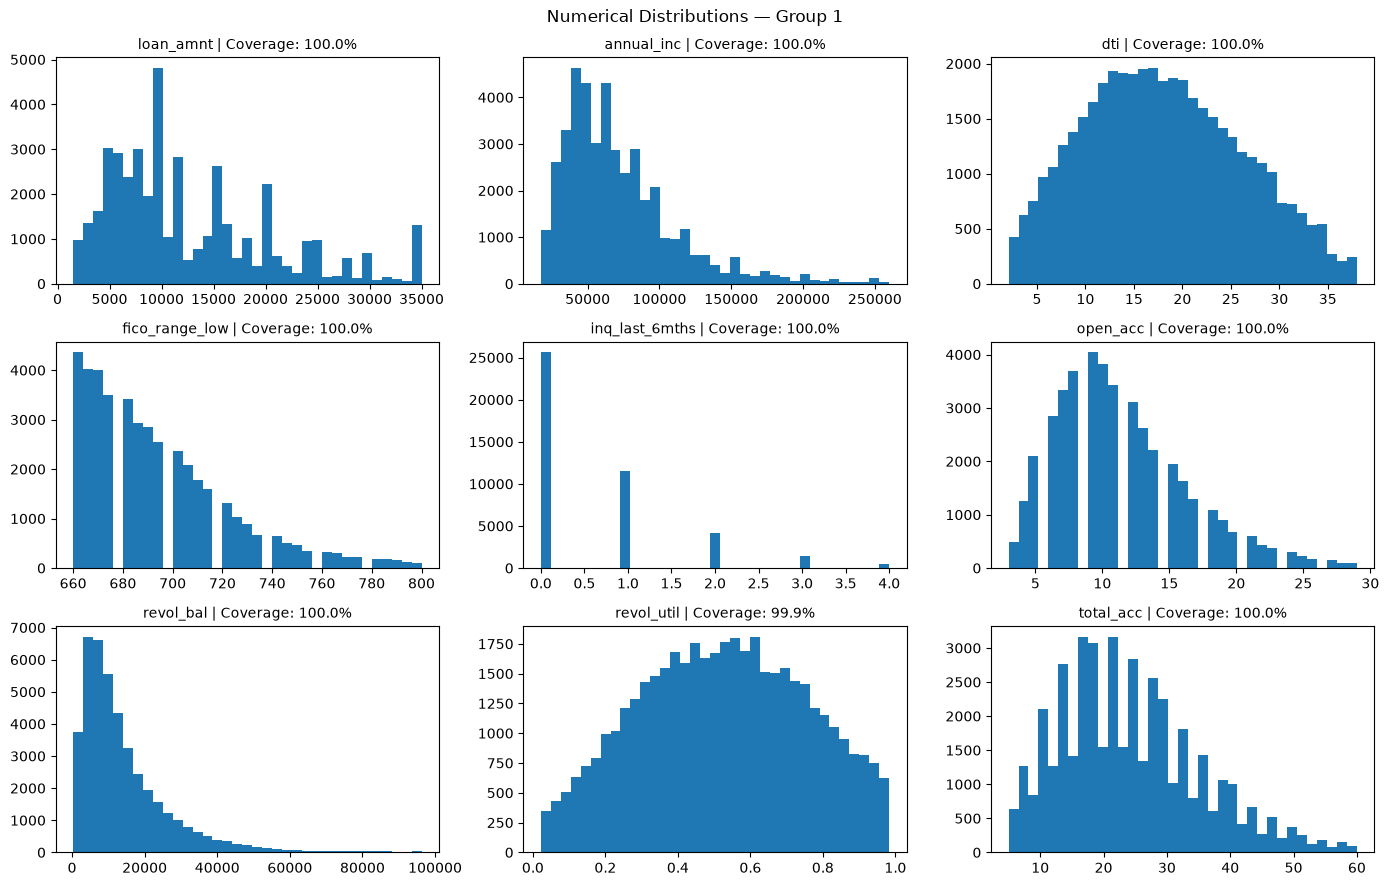

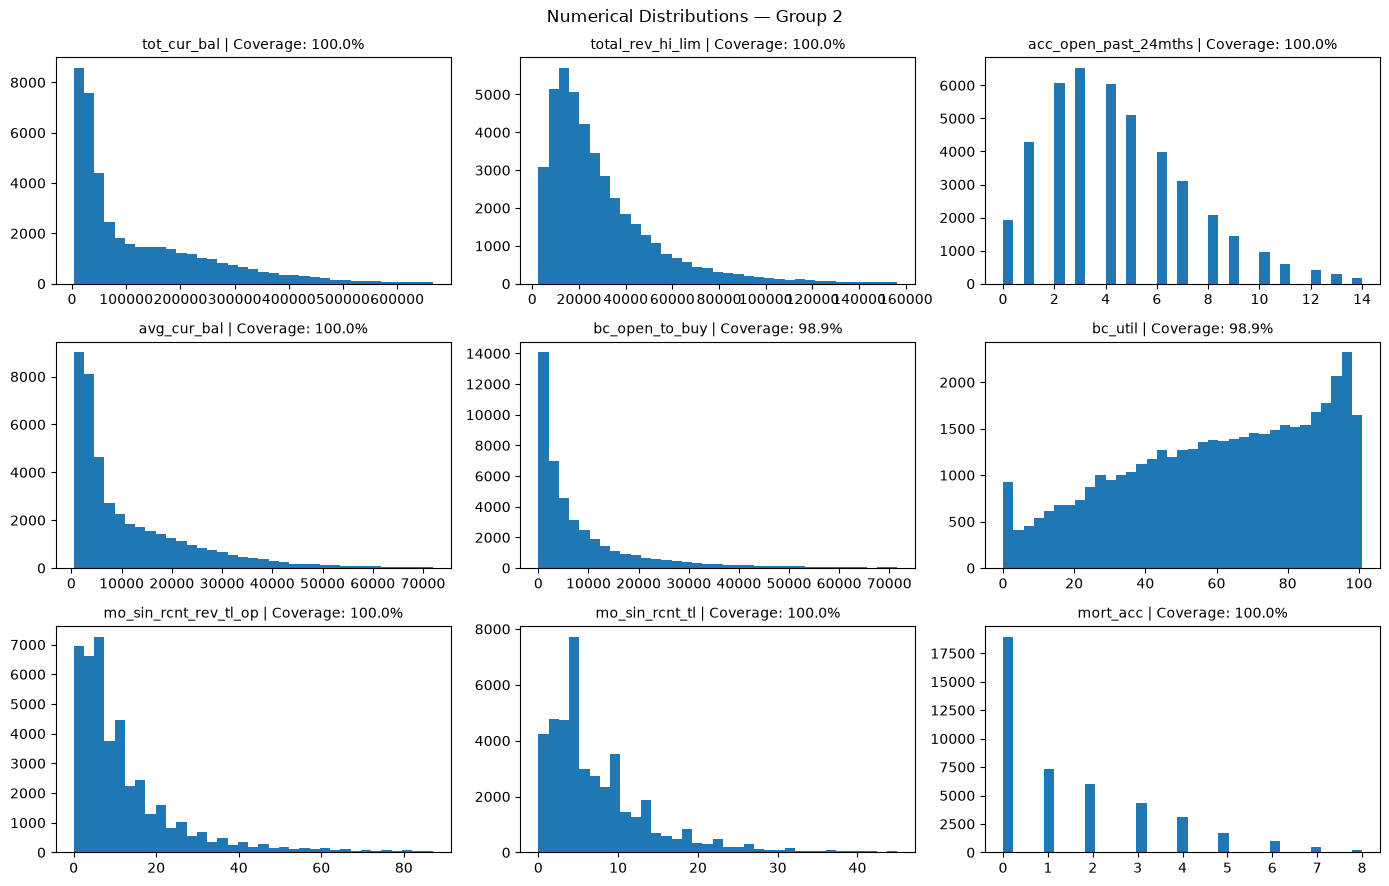

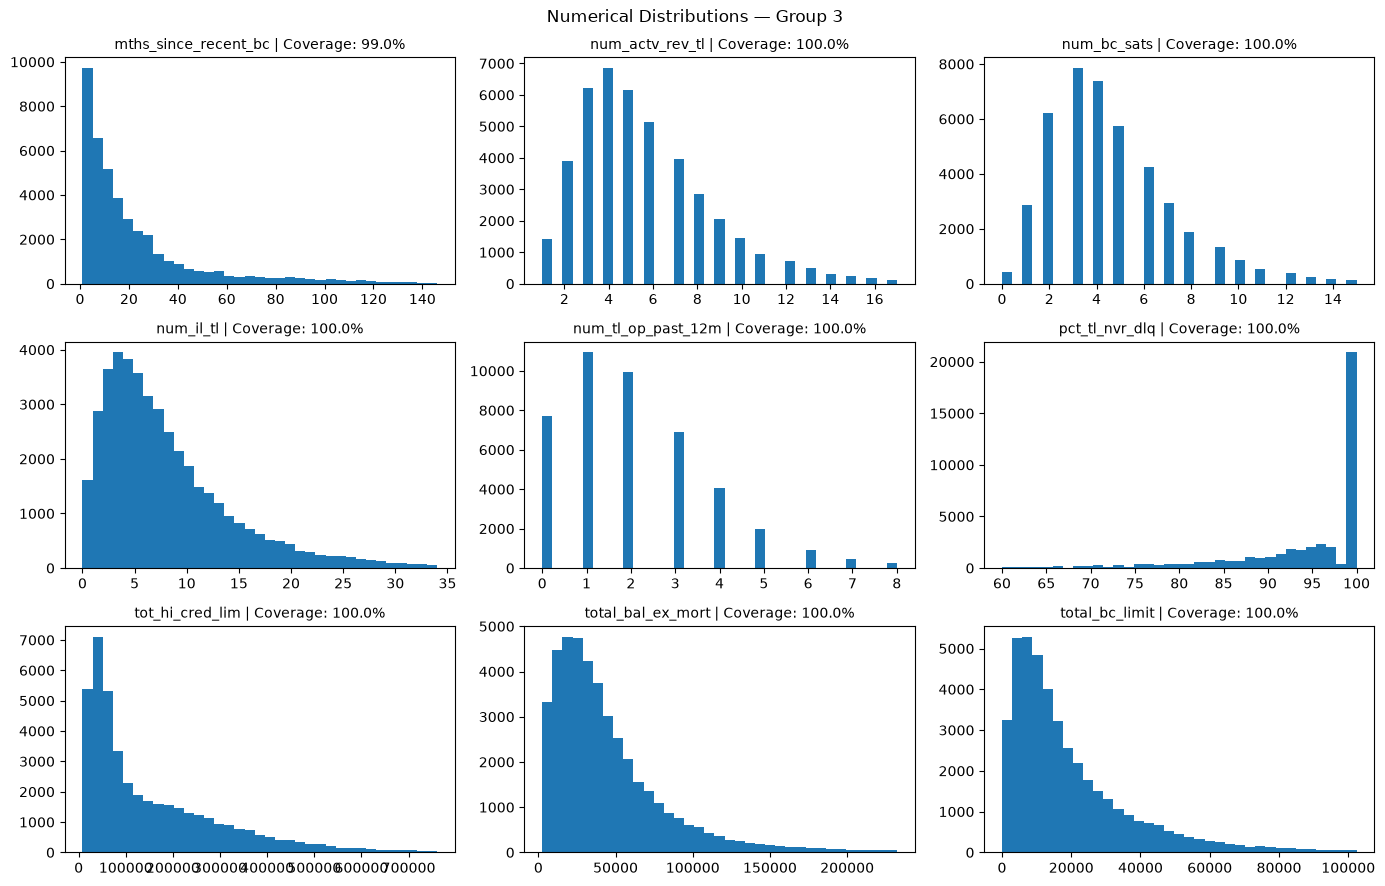

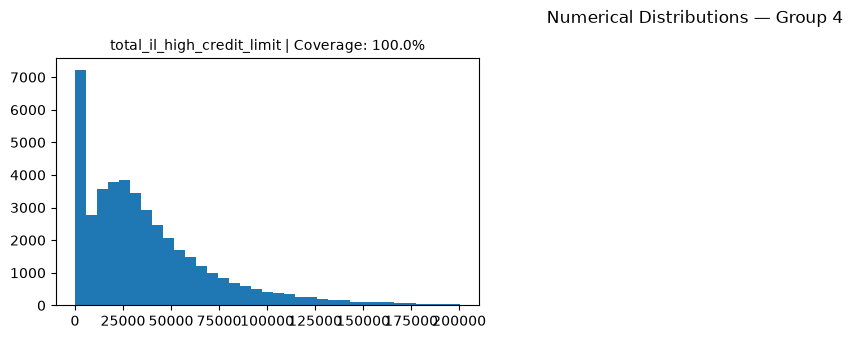

In [14]:
# 2.3.2 — Plot informative distributions

stats = numeric_summary.set_index("feature")

# Deterministic sample for visualization only
plot_sample = (
    df.with_row_index("_eda_row")
    .filter(pl.col("_eda_row") % 20 == 0)
    .select(detailed)
    .collect()
    .to_pandas()
)

for start in range(0, len(detailed), 9):

    group = detailed[start:start + 9]
    fig, axes = plt.subplots(3, 3, figsize=(14, 9))

    for ax, col in zip(axes.flat, group):

        values = pd.to_numeric(
            plot_sample[col], errors="coerce"
        )

        # Match the provisional -1 rule from Section 2.2
        values = values.replace(
            [-1, np.inf, -np.inf], np.nan
        ).dropna()

        # Bounds calculated on the entire cohort
        low = stats.loc[col, "p01"]
        high = stats.loc[col, "p99"]

        if pd.notna(low) and pd.notna(high) and low < high:
            values = values[values.between(low, high)]

        if len(values):
            ax.hist(values, bins=35)

        coverage = stats.loc[col, "coverage_pct"]

        ax.set_title(
            f"{col} | Coverage: {coverage:.1f}%",
            fontsize=10
        )

    for ax in axes.flat[len(group):]:
        ax.set_visible(False)

    fig.suptitle(
        f"Numerical Distributions — Group {1 + start // 9}"
    )

    plt.tight_layout()
    plt.show()

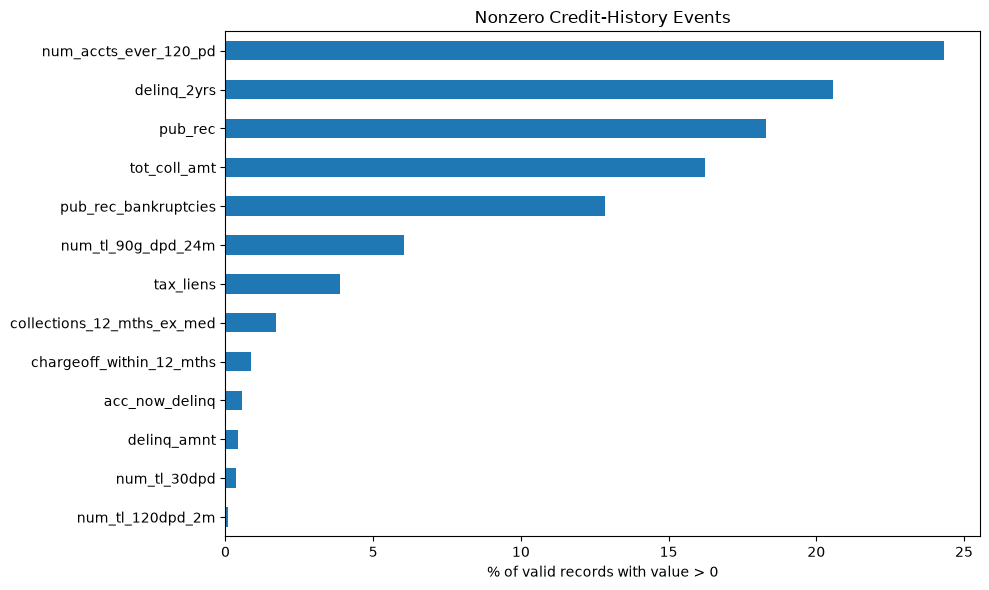

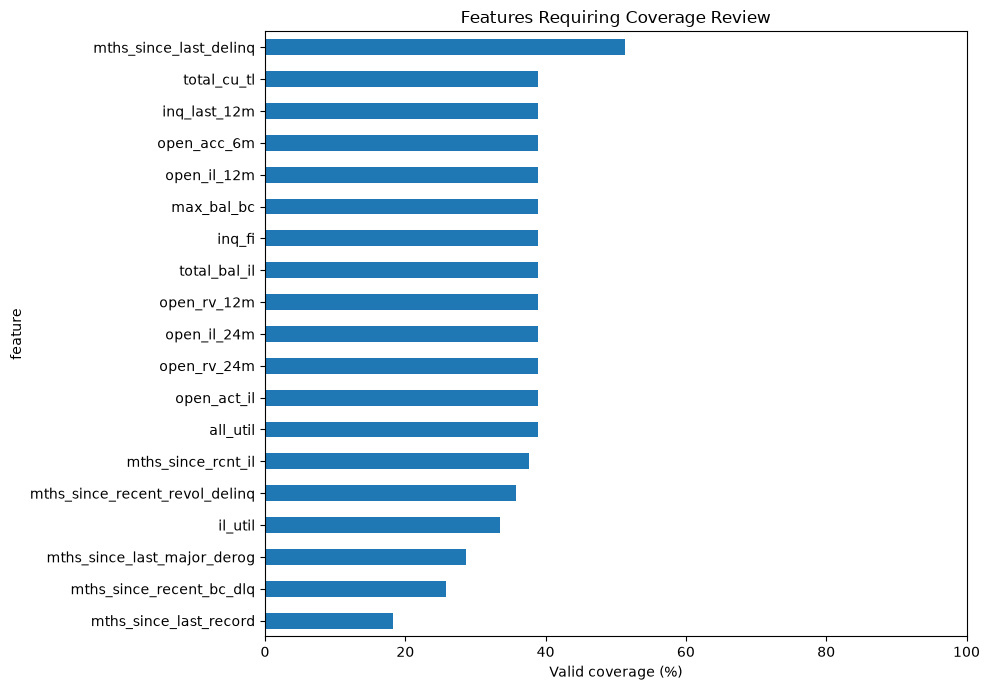

In [15]:
# 2.3.3 — Compare zero-heavy features

expressions = []

for col in zero_heavy:
    x = pl.col(col).cast(pl.Float64, strict=False)

    valid = (
        x.is_finite() & (x != -1)
    ).fill_null(False)

    expressions.append(
        (
            100
            * ((x > 0) & valid).fill_null(False).sum()
            / valid.sum()
        ).alias(col)
    )

if expressions:
    result = df.select(expressions).collect().row(
        0, named=True
    )

    nonzero_pct = pd.Series(result).sort_values()

    ax = nonzero_pct.plot.barh(
        figsize=(10, 6)
    )

    ax.set_xlabel("% of valid records with value > 0")
    ax.set_title("Nonzero Credit-History Events")

    plt.tight_layout()
    plt.show()


# Compare coverage for incomplete numerical features

coverage = (
    plot_plan.set_index("feature")
    .loc[coverage_features, "coverage_pct"]
    .sort_values()
)

ax = coverage.plot.barh(figsize=(10, 7))

ax.set_xlim(0, 100)
ax.set_xlabel("Valid coverage (%)")
ax.set_title("Features Requiring Coverage Review")

plt.tight_layout()
plt.show()

### 2.4 Outlier Investigation

**Objective:** Identify potential extreme observations and suspicious values.

We reuse the quartiles and valid observation counts computed in Section 2.2.

IQR diagnostics are calculated for features with sufficient coverage and
nonzero IQR. Sparse count variables and low-coverage features require
different investigations.

Outlier flags are descriptive, not automatic removal decisions.

We also perform basic domain checks because IQR alone cannot detect every
invalid value.

No original values are changed.

In [16]:
# 2.4 — IQR diagnostics using Section 2.2 results

eligible = plot_plan[
    plot_plan["coverage_pct"].ge(80)
    & plot_plan["q3"].gt(plot_plan["q1"])
    & plot_plan["valid_count"].ge(30)
].copy()

bounds = {}

for _, row in eligible.iterrows():

    iqr = row["q3"] - row["q1"]

    bounds[row["feature"]] = (
        row["q1"] - 1.5 * iqr,
        row["q3"] + 1.5 * iqr
    )


outlier_counts = {}
features = list(bounds)

for start in range(0, len(features), 8):

    group = features[start:start + 8]
    expressions = []

    for col in group:

        lower, upper = bounds[col]

        x = pl.col(col).cast(pl.Float64, strict=False)

        valid = (
            x.is_finite() & (x != -1)
        ).fill_null(False)

        expressions.append(
            pl.when(valid)
            .then((x < lower) | (x > upper))
            .otherwise(False)
            .sum()
            .alias(col)
        )

    result = df.select(expressions).collect().row(
        0, named=True
    )

    outlier_counts.update(result)


eligible["iqr_flags"] = (
    eligible["feature"].map(outlier_counts)
)

eligible["iqr_flag_pct_of_valid"] = (
    100
    * eligible["iqr_flags"]
    / eligible["valid_count"]
)

display(
    eligible[
        [
            "feature",
            "coverage_pct",
            "skewness",
            "iqr_flags",
            "iqr_flag_pct_of_valid"
        ]
    ]
    .sort_values(
        "iqr_flag_pct_of_valid",
        ascending=False
    )
    .round(2)
)

,feature,coverage_pct,skewness,iqr_flags,iqr_flag_pct_of_valid
47,mths_since_recent_bc,99.01,3.38,79933,9.28
38,bc_open_to_buy,98.95,3.88,76623,8.91
44,mo_sin_rcnt_rev_tl_op,100.00,3.45,68428,7.87
45,mo_sin_rcnt_tl,100.00,4.36,57485,6.61
12,revol_bal,100.00,15.43,56600,6.51
65,pct_tl_nvr_dlq,99.99,-2.13,56165,6.46
71,total_bc_limit,100.00,3.03,55735,6.41
32,total_rev_hi_lim,100.00,66.24,53743,6.18
70,total_bal_ex_mort,100.00,4.53,52536,6.04
37,avg_cur_bal,100.00,4.25,51425,5.91


In [17]:
# 2.4.1 — Check unusual financial values

dti = pl.col("dti").cast(pl.Float64, strict=False)
revol = pl.col("revol_util").cast(pl.Float64, strict=False)
inc = pl.col("annual_inc").cast(pl.Float64, strict=False)

checks = df.select(
    (
        (dti < 0) & (dti != -1)
    ).fill_null(False).sum().alias(
        "negative_dti_excluding_minus_one"
    ),

    (dti > 100).fill_null(False).sum().alias(
        "dti_above_100_review"
    ),

    (revol > 1).fill_null(False).sum().alias(
        "revol_util_above_100pct_review"
    ),

    (inc < 0).fill_null(False).sum().alias(
        "negative_annual_income"
    )
).collect().row(0, named=True)

display(
    pd.DataFrame({
        "check": list(checks),
        "rows": list(checks.values())
    })
)

,check,rows
0,negative_dti_excluding_minus_one,43
1,dti_above_100_review,90
2,revol_util_above_100pct_review,3391
3,negative_annual_income,0


In [18]:
# Cohort-specific year-wise feature coverage

# Reuse df and numeric_summary from earlier cells

features_to_check = numeric_summary.loc[
    numeric_summary["coverage_pct"] < 99,
    "feature"
].tolist()

expressions = [pl.len().alias("loans")]

for col in features_to_check:
    x = pl.col(col).cast(pl.Float64, strict=False)

    valid = (
        x.is_finite().fill_null(False)
        & (x != -1).fill_null(False)
    )

    expressions.append(
        (100 * valid.mean()).round(2).alias(col)
    )

year_coverage = (
    df.with_columns(
        pl.col("issue_d").dt.year().alias("issue_year")
    )
    .group_by("issue_year")
    .agg(expressions)
    .sort("issue_year")
    .collect()
)

display(
    year_coverage
    .to_pandas()
    .set_index("issue_year")
    .T
)

issue_year,2013,2014,2015,2016
loans,100422.00,162570.00,283173.00,323375.00
mths_since_last_delinq,43.53,51.08,52.01,53.16
mths_since_last_record,12.60,18.93,18.67,19.41
mths_since_last_major_derog,20.49,29.25,30.20,29.36
open_acc_6m,0.00,0.00,5.27,99.99
open_act_il,0.00,0.00,5.27,99.99
open_il_12m,0.00,0.00,5.27,99.99
open_il_24m,0.00,0.00,5.27,99.99
mths_since_rcnt_il,0.00,0.00,5.11,96.87
total_bal_il,0.00,0.00,5.27,99.99
